# Does a LoRA on every decomposed matrix lift onto the subcomponents as well as a full fine-tune?

**The answer.** Not shown yet. A rank-8 LoRA on every decomposed matrix, lifted onto the subcomponents, stayed within the noise of VPD's adversarial check at the step it learned the task. The fine-tune's lift read five times worse, but it was measured eight steps later. An earlier run shows the fine-tune's lift also within the noise at the LoRA's step. The LoRA's lift left about a fifth of the trigger behaviour in Δ, because its read side stayed random.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

EXP = Path('../experiments')
res = json.loads((EXP / 'lora_matched/results/lora_matched.json').read_text())
pred = json.loads((EXP / 'lora_matched/results/predictions.json').read_text())
earlier_lift = json.loads((EXP / 'lift_test/results/lift_faith.json').read_text())     # full fine-tune lift by step, same card
one_matrix = json.loads((EXP / 'lora_commute/results/lora_commute.json').read_text())  # LoRA on h.2.mlp.down_proj only

FT, L0, L1, W0, SC = res['ft'], res['lora_s0'], res['lora_s1'], res['W0'], res['score']
NONSAT = set(W0['non_saturated'])
BAND_TOP = 1 + 3 * W0['pgd_floor']  # unchanged decomposition plus three noise floors
COL = {'LoRA': '#2a78d6', 'LoRA seed 1': '#1baf7a', 'ft': '#eb6834', 'ref': '#7f7f7f', 'band': '#d9d9d6'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.titlesize': 11, 'font.size': 9, 'legend.fontsize': 8, 'figure.dpi': 110})

# (label, colour, record with 'lift'/'nothing'/'inexpressible', step)
STATES = {
    'ft': ('full fine-tune, step 10', COL['ft'], FT['measured'], FT['step']),
    'lora2': ('LoRA seed 0, step 2', COL['LoRA'], L0['steps']['2'], 2),
    'lora2s1': ('LoRA seed 1, step 2', COL['LoRA seed 1'], L1['steps']['2'], 2),
    'lora100': ('LoRA seed 0, step 100', COL['LoRA'], L0['steps']['100'], 100),
    'lora100s1': ('LoRA seed 1, step 100', COL['LoRA seed 1'], L1['steps']['100'], 100),
}


def energy_summary(per):
    # energy on the saturated matrices; inexpressible share over all 24; pooled share and null over the 20 others
    E = sum(p['energy'] for p in per.values())
    En = sum(p['energy'] for k, p in per.items() if k in NONSAT)
    return {'saturated': sum(p['energy'] for k, p in per.items() if k not in NONSAT) / E,
            'all': sum(p['omega_act'] * p['energy'] for p in per.values()) / E,
            'pooled': sum(p['omega_act'] * p['energy'] for k, p in per.items() if k in NONSAT) / En,
            'null': sum(p['null_act'] * p['energy'] for k, p in per.items() if k in NONSAT) / En}


SUM = {k: energy_summary(rec['inexpressible']['per_matrix']) for k, (_, _, rec, _) in STATES.items()}
gain_in_delta = lambda rec: rec['routes']['shares']['e_delta']

## What we were trying to test

Symbols used throughout:

- $W_0$: the weights of the target model, a 67M-parameter language model with four layers, before any training.
- $U_c, V_c$: the write and read vectors of subcomponent $c$. Each decomposed matrix is $W = \sum_c U_c V_c^\top + \Delta$.
- $\Delta$: the residual, the part of a weight matrix that no subcomponent carries.
- $\Gamma$: VPD's causal-importance function. It sets each subcomponent's mask from the model's activations and stays frozen here.
- $\delta W$: the change that training makes to one weight matrix.
- $O(\delta W) = (I - P_U)\,\delta W\,(I - P_V)$: the obstruction. It is the part of $\delta W$ that no first-order change of the alive subcomponents can express. $P_U$ and $P_V$ project onto the spans of the alive write and read vectors.

We start from the released VPD decomposition, which is faithful to $W_0$. We teach the model one behaviour: after a fixed emoticon trigger, predict the token `o`. There are 365 training windows and 73 held-out windows.

Two updates learn it. A rank-8 LoRA sits on all 24 decomposed matrices, the placement LoRAs normally get, with $\delta W = BA$ per matrix. Its read factor $A$ starts random and $B$ starts at zero. A full-weight fine-tune of the same matrices is the comparison. The LoRA is measured at the first checkpoint where held-out $P(o)$ reaches 0.9, which was step 2 for both seeds. The fine-tune is measured at step 10, the step earlier runs used.

Why this run: an earlier run put the LoRA on one matrix, `h.2.mlp.down_proj`, which the decomposition reads poorly. It compared that LoRA with a fine-tune of all 24 matrices, so it could not tell the LoRA apart from its site. Here both updates sit on the same matrices.

Each update is handed to two maps.

- **The lift** writes $\delta W$ as the least-norm $(dU, dV)$ with $dU\,V^\top + U\,dV^\top = \delta W - O(\delta W)$, and leaves the obstruction in $\Delta$.
- **Do-nothing** puts all of $\delta W$ in $\Delta$ and leaves the subcomponents alone. `GOALS.md` rules this map out, so it is the reference for an update that $\Delta$ absorbed.

Three measurements:

- **Inexpressible share**, $\mathbb E\|O(\delta W)\,a\|^2 / \mathbb E\|\delta W\,a\|^2$ with $a$ the matrix's input on the training windows. It reads 0 when the subcomponents can express the whole update and 1 when they can express none of it. Its isotropic null is the same share for a random update of that matrix. On four matrices the alive read and write vectors span every direction, so the share is 0 for any update; we call them saturated. Pooled values are weighted by the update's energy over the other 20 matrices.
- **Share of the gain left in Δ.** Training raises the log-odds of `o` at the trigger. With $\ell_{\rm t}$ the target model's log-odds and $\ell_{\rm s}$ the subcomponents' log-odds without masks, the share is the change in $\ell_{\rm t} - \ell_{\rm s}$ divided by the change in $\ell_{\rm t}$. It reads 0 when the subcomponents carry the whole gain, and 1 for do-nothing.
- **Pile faithfulness ratio.** VPD's own checks on 256 Pile rows: stochastic-mask, CI-masked and adversarial-mask reconstruction KL. Each is divided by the unchanged decomposition's value on $W_0$, so 1 means as faithful as before training. The adversarial mask comes from 20 steps of gradient ascent on the KL.

| state | what it is | what it rules out |
|---|---|---|
| fine-tune, lifted | positive control | an earlier run on the same card read 5.41; reproducing it checks the harness |
| fine-tune, do-nothing | reference | how far the update alone moves the Pile checks |
| LoRA seed 0, lifted | the arm under test | |
| LoRA seed 0, do-nothing | reference | whether an update this small passes the Pile checks whatever map is used |
| LoRA seed 1, lifted | second initialisation and batch order | seed noise in the shares |
| random update of each matrix | isotropic null | whether the subcomponents read the update better than chance |
| $W_0$ under three adversary seeds | noise floor | adversarial ratios that differ only by the search's luck |

## What we expected, and why

Four predictions were filed before any arm was trained.

- **The LoRA's read side stays random.** A LoRA's $A$ barely moves in the few steps it takes to learn. In the one-matrix run its rows kept a cosine of 0.92 to 0.98 with their start. So on the 20 non-saturated matrices we expected the update to be about as inexpressible as a random one: at least 0.8 of the null.
- **The lift leaves at least 0.3 of the gain in Δ.** This follows from the first prediction. What the subcomponents cannot read stays in $\Delta$ and carries its share of the behaviour. The one-matrix LoRA left 0.33 to 0.43 there, and the fine-tune's lift leaves 0.09. The filed caveat was that energy landing on the saturated matrices could pull it below 0.3.
- **The lifted LoRA is as fragile as the lifted fine-tune.** In earlier runs the adversarial ratio grew with the number of lifted matrices. It read 2.0 for one matrix and 5.4 for all 24. So we expected at least 5. The null was a ratio of at most 2 with less than 0.2 of the gain in Δ.
- **The direct share stays flat.** The direct share is the part of the gain carried by changed subcomponents under $W_0$'s CI values. It read 0.05 to 0.11 in every earlier run, whatever the update or map. We expected the LoRA and fine-tune lifts to differ by less than 0.1.

## What we observed

### Can the subcomponents express the LoRA's update better than a random update?

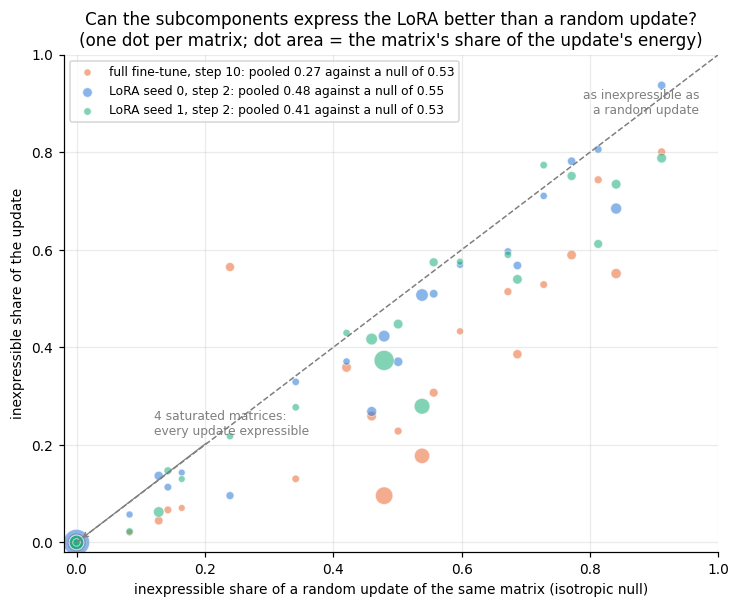

In [2]:
fig, ax = plt.subplots(figsize=(6.8, 5.6))
ax.plot([0, 1], [0, 1], color=COL['ref'], lw=1, ls='--')
ax.text(0.97, 0.93, 'as inexpressible as\na random update', ha='right', va='top', color=COL['ref'], fontsize=8)
for key in ('ft', 'lora2', 'lora2s1'):
    label, col, rec, _ = STATES[key]
    per = rec['inexpressible']['per_matrix']
    s = SUM[key]
    xs = [per[k]['null_act'] for k in per]; ys = [per[k]['omega_act'] for k in per]
    sizes = [20 + 600 * per[k]['energy_share'] for k in per]
    ax.scatter(xs, ys, s=sizes, color=col, alpha=0.55, edgecolor='white', linewidth=0.6,
               label=f"{label}: pooled {s['pooled']:.2f} against a null of {s['null']:.2f}")
ax.annotate('4 saturated matrices:\nevery update expressible', xy=(0.005, 0.005), xytext=(0.12, 0.22),
            fontsize=8, color=COL['ref'], arrowprops=dict(arrowstyle='->', color=COL['ref'], lw=0.8))
ax.set_xlim(-0.02, 1); ax.set_ylim(-0.02, 1)
ax.set_xlabel('inexpressible share of a random update of the same matrix (isotropic null)')
ax.set_ylabel("inexpressible share of the update")
ax.set_title('Can the subcomponents express the LoRA better than a random update?\n'
             '(one dot per matrix; dot area = the matrix\'s share of the update\'s energy)')
leg = ax.legend(loc='upper left', markerscale=0.5); plt.tight_layout(); plt.show()

**Reading it.** Barely. Pooled over the 20 non-saturated matrices, the subcomponents cannot express 0.48 of the LoRA's update, against 0.55 for a random update of the same matrices. Most blue and green dots sit on or just under the dashed line, where an update is as inexpressible as a random one. The full fine-tune's orange dots sit clearly below it, at about half the random share. The second seed reads 0.77 of random against the first seed's 0.86, just under the filed 0.8 line. Only the first seed was scored. The cause is that the read factor $A$ barely moved: its rows kept a cosine of 0.9997 with their random start. The four saturated matrices at the origin are left out of the pooled number, since every update is expressible there.

### How much of the behaviour does each lift leave in Δ, and does it follow the inexpressible energy?

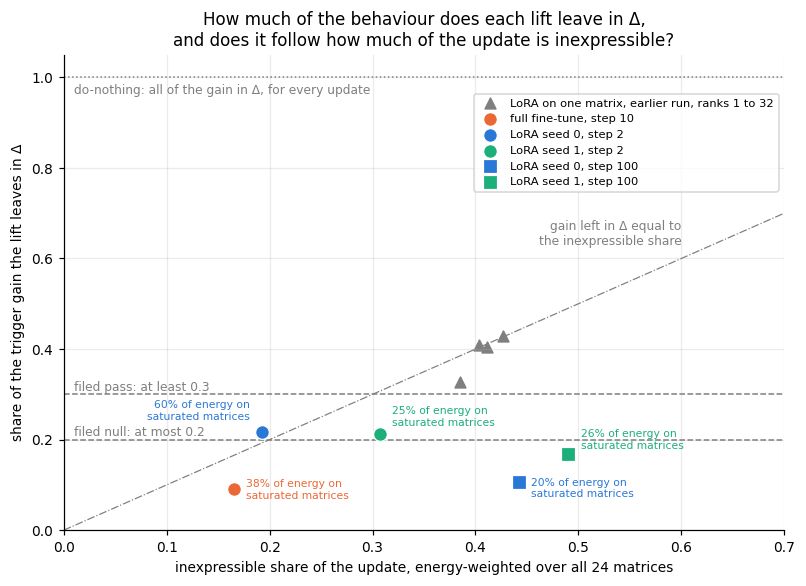

| update | energy on the 4 saturated matrices | inexpressible, all 24 matrices | inexpressible ÷ null, 20 others | gain left in Δ by the lift |
|---|---|---|---|---|
| full fine-tune, step 10 | 38% | 0.17 | 0.50 | 0.09 |
| LoRA seed 0, step 2 | 60% | 0.19 | 0.86 | 0.22 |
| LoRA seed 1, step 2 | 25% | 0.31 | 0.77 | 0.21 |
| LoRA seed 0, step 100 | 20% | 0.44 | 0.82 | 0.11 |
| LoRA seed 1, step 100 | 26% | 0.49 | 1.11 | 0.17 |

In [3]:
fig, ax = plt.subplots(figsize=(7.4, 5.4))
ax.plot([0, 0.7], [0, 0.7], color=COL['ref'], lw=0.8, ls='-.')
ax.text(0.6, 0.63, 'gain left in Δ equal to\nthe inexpressible share', ha='right', fontsize=8, color=COL['ref'])
ax.axhline(1.0, color=COL['ref'], lw=1, ls=':')
ax.text(0.01, 0.985, 'do-nothing: all of the gain in Δ, for every update', va='top', fontsize=8, color=COL['ref'])
for y, txt in ((0.2, 'filed null: at most 0.2'), (0.3, 'filed pass: at least 0.3')):
    ax.axhline(y, color=COL['ref'], lw=1, ls='--')
    ax.text(0.01, y + 0.008, txt, ha='left', fontsize=8, color=COL['ref'])
for rank, v in one_matrix['lora'].items():
    st = v['steps'][str(v['scored_step'])]
    ax.scatter(st['inexpressible']['pooled'], gain_in_delta(st['lift']), marker='^', s=50, color=COL['ref'],
               label='LoRA on one matrix, earlier run, ranks 1 to 32' if rank == '1' else None)
OFFSET = {'ft': (8, -6), 'lora2': (-8, 8), 'lora2s1': (8, 6), 'lora100': (8, -10), 'lora100s1': (8, 4)}
for key, marker in (('ft', 'o'), ('lora2', 'o'), ('lora2s1', 'o'), ('lora100', 's'), ('lora100s1', 's')):
    label, col, rec, _ = STATES[key]
    x, y = SUM[key]['all'], gain_in_delta(rec['lift'])
    ax.scatter(x, y, marker=marker, s=80, color=col, edgecolor='white', linewidth=0.8, zorder=3, label=label)
    dx, dy = OFFSET[key]
    ax.annotate(f"{SUM[key]['saturated']:.0%} of energy on\nsaturated matrices", (x, y), xytext=(dx, dy),
                textcoords='offset points', fontsize=7, color=col, ha='right' if dx < 0 else 'left')
ax.set_xlim(0, 0.7); ax.set_ylim(0, 1.05)
ax.set_xlabel("inexpressible share of the update, energy-weighted over all 24 matrices")
ax.set_ylabel('share of the trigger gain the lift leaves in Δ')
ax.set_title('How much of the behaviour does each lift leave in Δ,\nand does it follow how much of the update is inexpressible?')
ax.legend(loc='upper right', bbox_to_anchor=(1.0, 0.93), fontsize=7.5); plt.tight_layout(); plt.show()

rows = ['| update | energy on the 4 saturated matrices | inexpressible, all 24 matrices | inexpressible ÷ null, 20 others | gain left in Δ by the lift |',
        '|---|---|---|---|---|']
for key, (label, _, rec, _) in STATES.items():
    s = SUM[key]
    rows.append(f"| {label} | {s['saturated']:.0%} | {s['all']:.2f} | {s['pooled'] / s['null']:.2f} | {gain_in_delta(rec['lift']):.2f} |")
display(Markdown('\n'.join(rows)))

**Reading it.** About a fifth, and the amount does not follow the inexpressible share. Both seeds at step 2 leave 0.21 to 0.22 of the gain in Δ, between the filed 0.2 and 0.3 lines. That is less than the one-matrix LoRA's third, the grey triangles, and more than twice the fine-tune's 0.09. The grey triangles lie on the diagonal, where the gain left in Δ equals the inexpressible share. The 24-matrix points do not. Seed 1 has half again as much inexpressible energy as seed 0 and leaves the same share of the gain. From step 2 to step 100 the inexpressible share doubles while the gain left in Δ falls. The share of energy on the saturated matrices does not explain it either: 60% for seed 0 and 25% for seed 1 give the same result.

### Is the lifted LoRA faithful under VPD's adversarial check, where the fine-tune's lift is not?

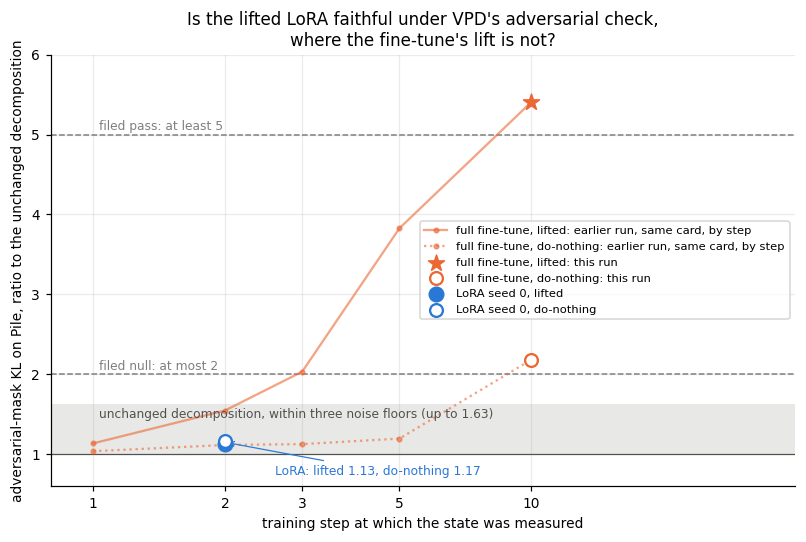

In [4]:
fig, ax = plt.subplots(figsize=(7.4, 5.0))
ax.axhspan(1, BAND_TOP, color=COL['band'], alpha=0.6, lw=0)
ax.axhline(1, color='#52514e', lw=0.8)
ax.text(1.03, BAND_TOP - 0.05, f'unchanged decomposition, within three noise floors (up to {BAND_TOP:.2f})', va='top', fontsize=8, color='#52514e')
for y, txt in ((2, 'filed null: at most 2'), (5, 'filed pass: at least 5')):
    ax.axhline(y, color=COL['ref'], lw=1, ls='--'); ax.text(1.03, y + 0.06, txt, fontsize=8, color=COL['ref'])
steps = sorted(earlier_lift['checkpoints'], key=int)
for arm, ls, lab in (('lift', '-', 'lifted'), ('do_nothing', ':', 'do-nothing')):
    ax.plot([int(s) for s in steps], [earlier_lift['checkpoints'][s]['ratios']['pgd_kl'][arm] for s in steps], ls=ls, marker='.',
            color=COL['ft'], alpha=0.6, label=f'full fine-tune, {lab}: earlier run, same card, by step')
ftm = FT['measured']
ax.scatter(FT['step'], ftm['lift']['pile']['pgd_kl'], s=120, marker='*', color=COL['ft'], zorder=4, label='full fine-tune, lifted: this run')
ax.scatter(FT['step'], ftm['nothing']['pile']['pgd_kl'], s=70, facecolor='white', edgecolor=COL['ft'], lw=1.5, zorder=4, label='full fine-tune, do-nothing: this run')
l2 = L0['steps']['2']
ax.scatter(2, l2['lift']['pile']['pgd_kl'], s=90, color=COL['LoRA'], zorder=5, label='LoRA seed 0, lifted')
ax.scatter(2, l2['nothing']['pile']['pgd_kl'], s=70, facecolor='white', edgecolor=COL['LoRA'], lw=1.5, zorder=5, label='LoRA seed 0, do-nothing')
ax.annotate(f"LoRA: lifted {l2['lift']['pile']['pgd_kl']:.2f}, do-nothing {l2['nothing']['pile']['pgd_kl']:.2f}", (2, 1.15),
            xytext=(2.6, 0.75), fontsize=8, color=COL['LoRA'], arrowprops=dict(arrowstyle='->', color=COL['LoRA'], lw=0.8))
ax.set_xscale('log'); ax.set_xticks([1, 2, 3, 5, 10], ['1', '2', '3', '5', '10']); ax.minorticks_off(); ax.set_xlim(0.8, 40)
ax.set_ylim(0.6, 6)  # whole range of every plotted value
ax.set_xlabel('training step at which the state was measured')
ax.set_ylabel('adversarial-mask KL on Pile, ratio to the unchanged decomposition')
ax.set_title("Is the lifted LoRA faithful under VPD's adversarial check,\nwhere the fine-tune's lift is not?")
ax.legend(loc='center right', fontsize=7.5); plt.tight_layout(); plt.show()

**Reading it.** Yes at step 2, but the fine-tune's lift was also faithful at step 2. The lifted LoRA reads 1.13 and its do-nothing 1.17, both inside the grey band of three noise floors. The fine-tune's lift reads 5.41 at step 10, matching the earlier run on the same card. The orange curve from that earlier run puts the fine-tune's lift at 1.55 at step 2, also inside the band. It leaves the band only at step 3. So the figure compares the LoRA early with the fine-tune late, and cannot say which update lifts better at equal training. The band is wide on this card, so the gap between the LoRA's lift and its do-nothing means nothing.

### Which part of the model carries the trigger gain in each state?

The gain splits exactly into five shares that sum to 1. The direct share is changed subcomponents under $W_0$'s CI values. The CI share is the unchanged subcomponents under the new CI values that $\Gamma$ assigns. The interaction is what the two produce together beyond their sum. The masked-off share is carried by subcomponents that $\Gamma$ masks off. The last share is left in $\Delta$.

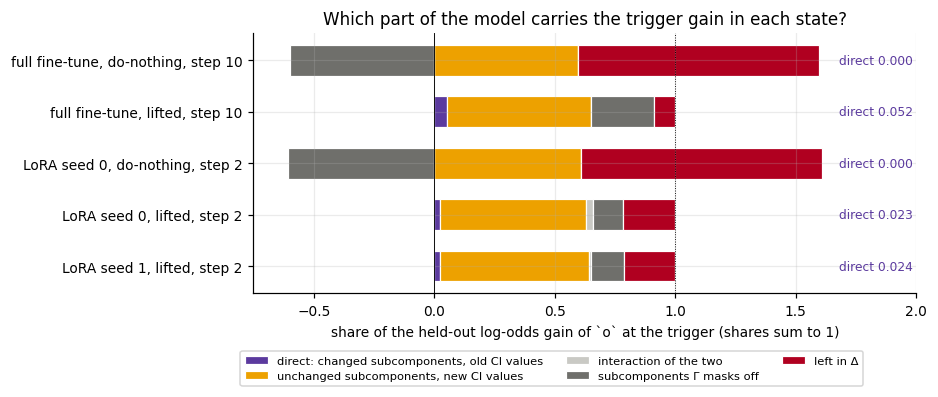

In [5]:
ROUTES = (('d', 'direct: changed subcomponents, old CI values', '#5b3a9e'),
          ('r', 'unchanged subcomponents, new CI values', '#eda100'),
          ('i', 'interaction of the two', '#c9c9c4'),
          ('e_gate', 'subcomponents Γ masks off', '#6f6f6b'),
          ('e_delta', 'left in Δ', '#b00020'))
bars = [('full fine-tune, do-nothing, step 10', FT['measured']['nothing']), ('full fine-tune, lifted, step 10', FT['measured']['lift']),
        ('LoRA seed 0, do-nothing, step 2', L0['steps']['2']['nothing']), ('LoRA seed 0, lifted, step 2', L0['steps']['2']['lift']),
        ('LoRA seed 1, lifted, step 2', L1['steps']['2']['lift'])]
fig, ax = plt.subplots(figsize=(8.6, 3.8))
y = np.arange(len(bars))[::-1]
pos, neg = np.zeros(len(bars)), np.zeros(len(bars))
for k, lab, col in ROUTES:
    v = np.array([rec['routes']['shares'][k] for _, rec in bars])
    left = np.where(v >= 0, pos, neg)
    ax.barh(y, v, left=left, color=col, label=lab, edgecolor='white', linewidth=0.8, height=0.6)
    pos += np.maximum(v, 0); neg += np.minimum(v, 0)
for yi, (_, rec) in zip(y, bars):
    ax.text(1.68, yi, f"direct {rec['routes']['shares']['d']:.3f}", va='center', fontsize=8, color='#5b3a9e')
ax.axvline(0, color='k', lw=0.6); ax.axvline(1, color='k', lw=0.6, ls=':')
ax.set_yticks(y); ax.set_yticklabels([b[0] for b in bars]); ax.set_xlim(-0.75, 2.0)
ax.set_xlabel('share of the held-out log-odds gain of `o` at the trigger (shares sum to 1)')
ax.set_title('Which part of the model carries the trigger gain in each state?')
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.2), ncol=3, fontsize=7.5); plt.tight_layout(); plt.show()

**Reading it.** Both lifts carry the trigger gain the same way: mostly through unchanged subcomponents under the new CI values that Γ assigns. That share is 0.60 for the fine-tune and 0.61 to 0.62 for the LoRA seeds. Changed subcomponents under the old CI values carry 0.02 for the LoRA and 0.05 for the fine-tune. That gap of 0.03 is inside the filed margin of 0.1. The lifts differ in the rest. The fine-tune's lift puts 0.26 in subcomponents Γ masks off and 0.09 in Δ, while the LoRA's puts about 0.13 and 0.22. In the do-nothing bars, the masked-off share is minus the new-CI share by construction, so it is not a finding.

## What we learned

A rank-8 LoRA placed on every decomposed matrix lifts with about a fifth of its trigger gain left in $\Delta$. The same LoRA on one poorly read matrix left a third or more. Its read side is still random: on the 20 non-saturated matrices the subcomponents express its update barely better than a random one. At the step it learns, its lifted decomposition passes VPD's Pile checks as well as the unchanged one does. That is the faithfulness half of the weak version in `GOALS.md`. Whether $\Delta$ absorbs too much is open, because `GOALS.md` fixes no threshold and a fifth is more than twice what the fine-tune's lift leaves. This run cannot say that a LoRA's lift survives where a fine-tune's breaks, because the two were measured at different points of training.

## How compelling is the evidence

- One task, the emoticon trigger, one LoRA rank and one learning rate.
- The Pile checks ran on seed 0 at step 2 only, and on the fine-tune at step 10 only.
- The adversarial search is noisy on this card. Three adversary seeds on $W_0$ spread by 21%, against 3.5% on the 4090 used in the one-matrix run. Only differences well outside the band can be read: the fine-tune's lift is one, the gap between the LoRA's lift and its do-nothing is not.
- The Pile checks are blind to a trigger-specific break. The adversary is shared over about 65,000 Pile positions that hold roughly three triggers.
- The share left in $\Delta$ is measured at the trigger only. The two seeds agree to 0.01 at step 2 and differ by 0.06 at step 100.
- The inexpressible share says nothing about behaviour by itself: an inexpressible part of the update can still be redundant.
- Both updates learned the task at a similar cost elsewhere. Held-out $P(o)$ was 0.96 for the LoRA at step 2 and 0.999 for the fine-tune. The KL on non-trigger positions was 0.059 and 0.055.

## Surprises

- **The lifted LoRA was not fragile.** We predicted an adversarial ratio of at least 5, like the fine-tune's lift. It read 1.13, inside the unchanged decomposition's noise band, while the fine-tune's lift read 5.41 in the same job. By the filed letter the verdict is "neither", because the null also required less than 0.2 of the gain in $\Delta$ and 0.218 was read. In direction the prediction reversed.
- **The second seed does not put its energy on the saturated matrices.** Seed 0 put three fifths of its update's energy there. The report gave that as the reason this lift leaves less in $\Delta$ than the one-matrix LoRA. Seed 1 put only a quarter there, and left the same share of the gain in $\Delta$. That explanation does not hold across seeds.
- **Energy and behaviour moved apart with training.** Between step 2 and step 100, seed 0's inexpressible share over all matrices more than doubled. Over the same steps the share of the gain left in $\Delta$ halved.
- **The fine-tune reproduced to three digits.** Its lifted and do-nothing ratios matched the earlier run on the same card. The measurement code was moved unchanged, so the 35% miss in the one-matrix run points to its different GPU.

## What next

- **The step-matched Pile comparison.** It was run afterwards in `experiments/lora_plateau` on an L40S, a different card. The lifted LoRA read 1.26 at step 10 and 1.22 at step 100. That card's band reaches only 1.14, and it has no fine-tune arm. A fine-tune lift on that card reading near 1 at step 10 would remove the contrast with the fine-tune; one reading near 5 would confirm it. See `notebooks/E09_lora_plateau.ipynb`.
- **The read-side check.** `experiments/lora_matched/read_side.py` asks whether the fine-tune's update reads the input directions the alive read vectors span, while the LoRA's reads random ones. Cluster jobs 22430 and 22431 were queued; `results/read_side.json` is not on disk yet. If the fine-tune reads inside the alive span and the LoRA does not, a LoRA whose $A$ starts in that span is the next arm, through `/design`.
- **Why the two seeds leave the same share in $\Delta$** with different energy on the saturated matrices. Until this is understood, the energy split should not be offered as the mechanism.

## Scorecard

Gates: G1, every arm learned. G2, every lift reproduces its target model's $P(o)$ to within 6e-4 and its shares sum to 1. G4, the fine-tune's ratios reproduce the earlier run's 2.18 and 5.41. G0 set $m = 0.1$ and the noise floor at 0.209.

In [6]:
claims = {'M1': ('the LoRA read side stays random', 'pooled inexpressible ÷ null ≥ 0.8; null ≤ 0.6', f"{SC['M1']['ratio']:.2f}"),
          'M2': ('the lift leaves the behaviour in Δ', 'share of gain in Δ ≥ 0.3; null ≤ 0.2', f"{SC['M2']['e_delta']:.3f}"),
          'C2m': ('the lifted LoRA is fragile like the fine-tune', 'PGD ratio ≥ 5; null ≤ 2 and gain in Δ ≤ 0.2',
                  f"{SC['C2m']['pgd_lora_lift']:.2f} vs fine-tune {SC['C2m']['pgd_ft_lift']:.2f}"),
          'C1m': ('the direct share is flat', f"difference < m = {SC['G0']['m']}", f"{SC['C1m']['d_lora_lift']:.3f} vs {SC['C1m']['d_ft_lift']:.3f}")}
verdict = lambda p: 'pass' if p['pass'] else ('null' if p['null'] else 'neither')
rows = ['| id | claim, filed as pass | rule | read | verdict |', '|---|---|---|---|---|']
for k, (claim, rule, read) in claims.items():
    v = verdict(SC[k]) + (', reversed in direction' if k == 'C2m' else '')
    rows.append(f'| {k} | {claim} | {rule} | {read} | {v} |')
display(Markdown('\n'.join(rows)))

| id | claim, filed as pass | rule | read | verdict |
|---|---|---|---|---|
| M1 | the LoRA read side stays random | pooled inexpressible ÷ null ≥ 0.8; null ≤ 0.6 | 0.86 | pass |
| M2 | the lift leaves the behaviour in Δ | share of gain in Δ ≥ 0.3; null ≤ 0.2 | 0.218 | neither |
| C2m | the lifted LoRA is fragile like the fine-tune | PGD ratio ≥ 5; null ≤ 2 and gain in Δ ≤ 0.2 | 1.13 vs fine-tune 5.41 | neither, reversed in direction |
| C1m | the direct share is flat | difference < m = 0.1 | 0.023 vs 0.052 | pass |

## Not run

- Pile ratios of the LoRA's lift and do-nothing at steps 10 and 100 in this job.
- Pile ratios of the fine-tune's lift at steps 1 to 3 in this job.
- Pile ratios for LoRA seed 1.
- More than three adversary seeds for the noise floor.
- The read-side check, queued as cluster jobs 22430 and 22431.
- VPD's sparsity loss on any lifted state; any task other than the emoticon; $\Gamma$ updating; the per-step lift with updated bases.

## Provenance

- Results: `experiments/lora_matched/results/lora_matched.json`; predictions `results/predictions.json`, filed before the run and unchanged.
- Reference curves: `experiments/lift_test/results/lift_faith.json` for the fine-tune by step, and `experiments/lora_commute/results/lora_commute.json` for the one-matrix LoRA.
- Code: `experiments/lora_matched/run.py` on `src/commute/harness.py`. Codex adversarial review before the run: approved, no findings.
- Compute: MATS cluster, one L40. Smoke job 22368 took 85 s; scored job 22371 took 18 minutes. Cost $0.
- Full tables and scoring: `reports/analyses/2026-10-19_analysis_lora-matched.md`.